
## Ottimizzazione e simulazione in condizioni di incertezza



Il modello Assembly to Order è un problema di programmazione stocastica a due stadi:    
- *primo stadio* (decisioni here-and-now): si decidono le quantità ottime di componenti base da produrre o acquistare prima di conoscere l'effettiva domanda dei prodotti finiti.   
- *Osservazione dell'incertezza*: La domanda si manifesta secondo una distribuzione di probabilità.
- *Secondo Stadio* (decisioni di recourse o wait-and-see): Una volta nota la domanda, decidi quanti prodotti finiti assemblare a partire dai componenti che si hanno a disposizione.

## Il modello:
Il problema è formulato come una massimizzazione del profitto atteso su un insieme di scenari $\mathcal{S}$. 

Insiemi:   
$\mathcal{I}$: insieme dei componenti.  
$\mathcal{J}$: insieme dei prodotti finiti.  
$\mathcal{M}$: insieme delle macchine.  
$\mathcal{S}$: insieme dei possibili esiti o scenari.  

Parametri:   
$C_i$: costo del componente $i$.    
$P_j$: prezzo di vendita del prodotto $j$.  
$L_m$: disponibilità temporale della macchina $m$.  
$T_{im}$: tempo necessario per produrre $i$ sulla macchina $m$.  
$G_{ij}$: fattore "gozinto", ovvero la quantità del componente $i$ necessaria per assemblare il prodotto $j$.  
$d_j^s$: domanda del prodotto $j$ nello scenario $s$.  
$\pi^s$: probabilità dello scenario $s$.  

Variabili:   
$x_i \ge 0$: quantità del componente $i$ prodotta (decisione here-and-now).   
$y_j^s \ge 0$: quantità del prodotto $j$ assemblata nello scenario $s$ (decisione wait-and-see).  


Formulazione:
$$\max \quad -\sum_{i \in \mathcal{I}} C_i x_i + \sum_{s \in \mathcal{S}} \pi^s \sum_{j \in \mathcal{J}} P_j y_j^s$$

Soggetto a:  
1) Vincolo di capacità produttiva: $\sum_{i \in \mathcal{I}} T_{im} x_i \le L_m \quad \forall m \in \mathcal{M}$.   
2) Vincolo di domanda massima: $y_j^s \le d_j^s \quad \forall j \in \mathcal{J}, \forall s \in \mathcal{S}$.    
3) Vincolo di disponibilità componenti (Distinta base): $\sum_{j \in \mathcal{J}} G_{ij} y_j^s \le x_i \quad \forall i \in \mathcal{I}, \forall s \in \mathcal{S}$.    
4) Non negatività: $y_j^s, x_i \ge 0$.

In [144]:
pip install gurobipy

Note: you may need to restart the kernel to use updated packages.


# PRODUZIONE BIKE

INSIEME DEI PRODOTTI FINITI J
1) Bike
2) E-City
3) E-MTB

INSIEMI DELLE MACCHINE M   
$M_1$: linea meccanica (tutte e tre coinvolte)     
$M_2$: linea elettrica (E-city, E-MTB)   

INSIEME DEI COMPONENTI I   
-$i_1$: Motore standard (250W) - usato solo per E-City | Prezzo: 200 €       
-$i_2$: Motore performante (500W) - usato solo per E-MTB | Prezzo: 400 €      
-$i_3$: Batteria base (500Wh) - usata per E-City | Prezzo: 325 €      
-$i_4$: Batteria ad alta capacità (750Wh) - usata per E-MTB | Prezzo: 575 €      
-$i_5$: Modulo controller elettronico - E-City E-MTB | Prezzo: 100 €     
-$i_6$: Ruote - condivise da tutte | Prezzo: 200 €      
-$i_7$: Sellino - condivise da tutte | Prezzo: 40 €      
-$i_8$: Manubrio base - usato solo per E-City e Bike | Prezzo: 25 €     
-$i_9$: Manubrio sportivo - usato solo per E-MTB | Prezzo: 70 €      
-$i_{10}$: Freno standard - usato solo per E-City e Bike | Prezzo: 50 €      
-$i_{11}$: Freno sportivo - usato solo per E-MTB | Prezzo: 175 €      
-$i_{12}$: Telaio - condivise da tutte | Prezzo: 325 €      
-$i_{13}$: Display elettronico - E-City E-MTB | Prezzo: 80 €      
-$i_{14}$: Fari - condivise da tutte | Prezzo: 30 €       
-$i_{15}$: Cestello - usato solo per E-City e Bike | Prezzo: 20 €   

INSIEMI DEGLI SCENARI      
-$s_1$: Alta Domanda  -> $\pi^{s_1} = 0.30$     
-$s_2$: Medio Domanda -> $\pi^{s_2} = 0.50$    
-$s_3$: Bassa Domanda ->  $\pi^{s_3} = 0.20$    

PREZZI DI VENDITA    
-$P_1$: 999 €   
-$P_2$: 1999 €   
-$P_2$: 2999 €   


DISTRIBUZIONI DI DOMANDA       
$D: LN(\mu_1, \sigma_1)$ Alta Domanda     
$D: TN(\mu_2, \sigma_2)$ Media Domanda     
$D: LN(\mu_3, \sigma_3)$ Bassa Domanda     


DISPONIBILITA' TEMPORALE MACCHINE     
$L_{m_1}$ (Linea Meccanica produzione) = 15.000 minuti   
$L_{m_2}$ (Linea Elettronica produzione) = 15.000 minuti    


TEMPI DI PRODUZIONE DEL COMPONENTE i SULLA MACCHINA m   
T = {
    # Componente: { m1, m2}   
    'i1':  {'m1': 20,  'm2': 40},   
    'i2':  {'m1': 25,  'm2': 55},   
    'i3':  {'m1': 0,  'm2': 25},   
    'i4':  {'m1': 0,  'm2': 35},   
    'i5':  {'m1': 0,  'm2': 15},   
    'i6':  {'m1': 20, 'm2': 0},   
    'i7':  {'m1': 5,  'm2': 0},   
    'i8':  {'m1': 10, 'm2': 0},   
    'i9':  {'m1': 15, 'm2': 0},   
    'i10': {'m1': 15, 'm2': 0},   
    'i11': {'m1': 20, 'm2': 0},   
    'i12': {'m1': 60, 'm2': 0},  
    'i13': {'m1': 0,  'm2': 15},   
    'i14': {'m1': 5,  'm2': 5},   
    'i15': {'m1': 8,  'm2': 0}  
}


G = {  
    'i1':  {'j1': 0, 'j2': 1, 'j3': 0},   
    'i2':  {'j1': 0, 'j2': 0, 'j3': 1},   
    'i3':  {'j1': 0, 'j2': 1, 'j3': 0},   
    'i4':  {'j1': 0, 'j2': 0, 'j3': 1},   
    'i5':  {'j1': 0, 'j2': 1, 'j3': 1},   
    'i6':  {'j1': 2, 'j2': 2, 'j3': 2},   
    'i7':  {'j1': 1, 'j2': 1, 'j3': 1},   
    'i8':  {'j1': 1, 'j2': 1, 'j3': 0},   
    'i9':  {'j1': 0, 'j2': 0, 'j3': 1},   
    'i10': {'j1': 2, 'j2': 2, 'j3': 0},  
    'i11': {'j1': 0, 'j2': 0, 'j3': 2},   
    'i12': {'j1': 1, 'j2': 1, 'j3': 1},   
    'i13': {'j1': 0, 'j2': 1, 'j3': 1},  
    'i14': {'j1': 2, 'j2': 2, 'j3': 2},   
    'i15': {'j1': 1, 'j2': 1, 'j3': 0}   
}




# MODELLO ATO PER BIKE PRODUCTION

In [145]:
import numpy as np
from scipy import stats
import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt

set_seed = 32324
np.random.seed(set_seed)

In [146]:
# INSIEMI DEI PARAMETRI
components = [f'i{k}' for k in range(1, 16)]
products = ['j1', 'j2', 'j3']  # j1=Bike, j2=E-City, j3=E-MTB
machines = ['m1', 'm2']
scenarios = ['s1', 's2', 's3'] # Alta, Media, Bassa


# Probabilità degli scenari (pi^s)
pi = {'s1': 0.30, 's2': 0.50, 's3': 0.20}

# Costi dei componenti C[i]
C = {'i1': 200, 'i2': 400, 'i3': 325, 'i4': 575, 'i5': 100, 'i6': 200, 'i7': 40, 
     'i8': 25, 'i9': 70, 'i10': 50, 'i11': 175, 'i12': 325, 'i13': 80, 'i14': 30, 'i15': 20}

# Prezzi di vendita P[j]
P = {'j1': 999, 'j2': 1999, 'j3': 2999}

# Capacità macchine L[m] in minuti
L = {'m1': 15000, 'm2': 15000}

# Tempi di produzione T[i][m]
T = {
    # Componente: { m1, m2}
    'i1':  {'m1': 20,  'm2': 40},
    'i2':  {'m1': 25,  'm2': 55},
    'i3':  {'m1': 0,  'm2': 25},
    'i4':  {'m1': 0,  'm2': 35},
    'i5':  {'m1': 0,  'm2': 15},
    'i6':  {'m1': 20, 'm2': 0},
    'i7':  {'m1': 5,  'm2': 0},
    'i8':  {'m1': 10, 'm2': 0},
    'i9':  {'m1': 15, 'm2': 0},
    'i10': {'m1': 15, 'm2': 0},
    'i11': {'m1': 20, 'm2': 0},
    'i12': {'m1': 60, 'm2': 0},
    'i13': {'m1': 0,  'm2': 15},
    'i14': {'m1': 5,  'm2': 5},
    'i15': {'m1': 8,  'm2': 0}
}

#Quantià di i in j G[i][j]
G = {  
    'i1':  {'j1': 0, 'j2': 1, 'j3': 0},
    'i2':  {'j1': 0, 'j2': 0, 'j3': 1},
    'i3':  {'j1': 0, 'j2': 1, 'j3': 0},
    'i4':  {'j1': 0, 'j2': 0, 'j3': 1},
    'i5':  {'j1': 0, 'j2': 1, 'j3': 1},
    'i6':  {'j1': 2, 'j2': 2, 'j3': 2},
    'i7':  {'j1': 1, 'j2': 1, 'j3': 1},
    'i8':  {'j1': 1, 'j2': 1, 'j3': 0},
    'i9':  {'j1': 0, 'j2': 0, 'j3': 1},
    'i10': {'j1': 2, 'j2': 2, 'j3': 0},
    'i11': {'j1': 0, 'j2': 0, 'j3': 2},
    'i12': {'j1': 1, 'j2': 1, 'j3': 1},
    'i13': {'j1': 0, 'j2': 1, 'j3': 1},
    'i14': {'j1': 2, 'j2': 2, 'j3': 2},
    'i15': {'j1': 1, 'j2': 1, 'j3': 0}
}


Generiamo l'incertezza del problema, costruendo gli scenari di domanda per i tre prodotti finiti ($j_1, j_2, j_3$) al variare delle condizioni di mercato.

La funzione *target_to_lognormal* serve per utilizzare correttamente la distribuzione Lognormale in Python. La funzione np.random.lognormal(mu, sigma) di NumPy non accetta in ingresso la media e la deviazione standard della distribuzione finale che vogliamo ottenere, bensì i parametri $\mu$ e $\sigma$ della distribuzione Normale sottostante. Quindi bisogna applicare delle trasformazioni affinchè la domanda abbia esattamente la media *target_mean* e la deviazione standard *target_std*. 

$$\mu_{log} = \ln\left(\frac{\mu^2}{\sqrt{\sigma^2 + \mu^2}}\right)$$
$$\sigma_{log} = \sqrt{\ln\left(1 + \frac{\sigma^2}{\mu^2}\right)}$$

Invece la funzione *genera_domande_per_scenario* costruisce il set di dati che alimenterà il modello di programmazione stocastica (il "Secondo Stadio"). Genera un numero pari a sample_size di campioni per ogni combinazione di prodotto e scenario.   
Alla fine, la funzione raggruppa tutti i vettori generati in un dizionario annidato con struttura d['prodotto']['scenario'] che restituisce una lista di dimensione sample_size.



In [147]:
def target_to_lognormal(target_mean, target_std):
    """
    Converte la media e la deviazione standard desiderate (spazio reale) 
    nei parametri mu e sigma richiesti per generare la distribuzione Lognormale.
    """
    variance = target_std ** 2
    mu_log = np.log(target_mean ** 2 / np.sqrt(variance + target_mean ** 2))
    sigma_log = np.sqrt(np.log(1 + variance / target_mean ** 2))
    return mu_log, sigma_log

def genera_domande_per_scenario(sample_size):
    # s1: ALTA DOMANDA (Lognormale)
    mu_s1_j1, sig_s1_j1 = target_to_lognormal(300, 45)
    d_s1_j1 = np.round(np.random.lognormal(mu_s1_j1, sig_s1_j1, sample_size)).astype(int)
    mu_s1_j2, sig_s1_j2 = target_to_lognormal(200, 30)
    d_s1_j2 = np.round(np.random.lognormal(mu_s1_j2, sig_s1_j2, sample_size)).astype(int)
    mu_s1_j3, sig_s1_j3 = target_to_lognormal(150, 25)
    d_s1_j3 = np.round(np.random.lognormal(mu_s1_j3, sig_s1_j3, sample_size)).astype(int)
    
    # s2: MEDIA DOMANDA (Normale Troncata a 0)
    d_s2_j1 = np.round(np.maximum(0, np.random.normal(225, 20, sample_size))).astype(int)
    d_s2_j2 = np.round(np.maximum(0, np.random.normal(140, 15, sample_size))).astype(int)
    d_s2_j3 = np.round(np.maximum(0, np.random.normal(100, 10, sample_size))).astype(int)

    # s3: BASSA DOMANDA (Lognormale)
    mu_s3_j1, sig_s3_j1 = target_to_lognormal(150, 30)
    d_s3_j1 = np.round(np.random.lognormal(mu_s3_j1, sig_s3_j1, sample_size)).astype(int)
    mu_s3_j2, sig_s3_j2 = target_to_lognormal(80, 20)
    d_s3_j2 = np.round(np.random.lognormal(mu_s3_j2, sig_s3_j2, sample_size)).astype(int)
    mu_s3_j3, sig_s3_j3 = target_to_lognormal(50, 15)
    d_s3_j3 = np.round(np.random.lognormal(mu_s3_j3, sig_s3_j3, sample_size)).astype(int)

    # Costruiamo il dizionario d[j][s][w] sfruttando la conversione in lista
    d = {
        'j1': {
            's1': d_s1_j1.tolist(),
            's2': d_s2_j1.tolist(),
            's3': d_s3_j1.tolist()
        },
        'j2': {
            's1': d_s1_j2.tolist(),
            's2': d_s2_j2.tolist(),
            's3': d_s3_j2.tolist()
        },
        'j3': {
            's1': d_s1_j3.tolist(),
            's2': d_s2_j3.tolist(),
            's3': d_s3_j3.tolist()
        }
    }
    
    return d


MODELLO STOCASTICO A DUE STADI (ASSEMBLY TO ORDER)   
Il problema di ottimizzazione è stato formulato come un modello di Programmazione Stocastica a Due Stadi, con l'obiettivo di determinare una strategia di produzione here-and-now per i componenti base che massimizzi il profitto atteso, fronteggiando l'incertezza intrinseca della domanda di mercato.  

La risoluzione del modello è stata ottenuta mediante la tecnica di Sample Average Approximation (SAA), che permette di approssimare la distribuzione di probabilità continua della domanda attraverso un insieme discreto di scenari campionari.
L'integrazione di un indice triplo $(j, s, w)$ permette di modellare il vincolo di recourse (l'assemblaggio dei prodotti finiti) in modo che le decisioni di secondo stadio ($y$) siano coerenti con ogni singola realizzazione della domanda ($w$), assicurando che la disponibilità di componenti ($x$) sia sufficiente a coprire la variabilità della domanda reale.


In [148]:
# MODELLO ATO

def solve_bike_ato(scenari_domanda, pi, C, P, L, T, G, components, products, machines, scenarios, sample_size):
    
    model = gp.Model("ATO_Bike_Manufacturing")
    model.Params.OutputFlag = 0

    campioni = list(range(sample_size))

    # Variabili Stadio 1
    x = model.addVars(components, vtype=GRB.INTEGER, lb=0, name="x")
    
    # Variabili Stadio 2
    y = model.addVars(products, scenarios, campioni, vtype=GRB.INTEGER, lb=0, name="y")

    # Funzione obiettivo
    costo_produzione = gp.quicksum(C[i] * x[i] for i in components)

    # Ricavo atteso stratificato: probabilità dello scenario * (1/N) * somma ricavi dei campioni
    ricavo_atteso = gp.quicksum(
        pi[s] * P[j] * (y[j, s, w] / sample_size)
        for j in products 
        for s in scenarios 
        for w in campioni
    )

    model.setObjective(ricavo_atteso - costo_produzione, GRB.MAXIMIZE)

    
    # VINCOLI
    # 1) Vincolo Capacità
    for m in machines:
        model.addConstr(
            gp.quicksum(T[i][m] * x[i] for i in components) <= L[m],
            name=f"Capacita_{m}"
        )

    # 2) Vincolo Domanda Massima
    for j in products:
        for s in scenarios:
            for w in campioni:
                model.addConstr(
                    y[j, s, w] <= scenari_domanda[j][s][w],
                    name=f"Domanda_{j}_{s}_{w}"
                )


    # 3) Vincolo Distinta Base
    for i in components:
        for s in scenarios:
            for w in campioni:
                model.addConstr(
                    gp.quicksum(G[i][j] * y[j, s, w] for j in products) <= x[i],
                    name=f"Disponibilita_{i}_{s}_{w}"
                )

    model.optimize()

    # Salvataggio Dati
    x_sol = {i: x[i].X for i in components}
    
    # La soluzione y ora è mappata sulla tripla (j, s, w)
    y_sol = {(j, s, w): y[j, s, w].X for j in products for s in scenarios for w in campioni}

    return {
        "objective": model.ObjVal,
        "x": x_sol,
        "y": y_sol,
        "d": scenari_domanda,
        "model": model
    }

# STABILITA IN-SAMPLE
La stabilità in-sample è una metrica utilizzata nell'ottimizzazione stocastica per validare la qualità dell'approssimazione del problema basata su scenari. L'obiettivo è verificare che il numero di scenari ($sample_size$) sia sufficiente a rendere la soluzione indipendente dalla particolare estrazione casuale effettuata.   
Per farlo: 
1) generiamo due insiemi indipendenti di scenari, $\mathcal{S}$ e $\mathcal{S}'$, entrambi con la stessa cardinalità (numero di scenari, n_scenario). 
2) Procediamo risolvendo il problema di ottimizzazione per entrambi gli insiemi, ottenendo i valori ottimi della funzione obiettivo.   
3) Si ripete questa operazione $N$ volte per calcolare la differenza tra i risultati dei due insiemi, definendo $\phi_i = min_{x \in \mathcal{X}} f(x | \mathcal{S}_i) - min_{x \in \mathcal{X}} f(x | \mathcal{S}'_i)$. 
4) Poiché gli insiemi sono indipendenti, anche i risultati lo sono. Si utilizza il Teorema del Limite Centrale per verificare se la media delle differenze ($\overline{\phi}_N$) è statisticamente vicina allo zero. In questo caso abbiamo scelto anche un ulteriore criterio di arresto che si basa sull'ampiezza dell'intervallo di confidenza. Si richiede quindi che l'ampiezza sia inferiore a una certa tolleranza fissata.
$$0 \in \left[ \overline{\phi}_{N} - z_{1-\frac{\alpha}{2}} \frac{\sigma_{\phi}}{\sqrt{N}}, \overline{\phi}_{N} + z_{1-\frac{\alpha}{2}} \frac{\sigma_{\phi}}{\sqrt{N}} \right]$$

n     | Media Diff   | IC 95% Inf   | IC 95% Sup   | Ampiezza   | Tolleranza | Stabile
------------------------------------------------------------------------------------------
5     | 774.56       | -115.23      | 1664.35      | 1779.58    | 368.50     | False
8     | 267.34       | -349.75      | 884.43       | 1234.18    | 361.63     | False
11    | -167.56      | -660.02      | 324.91       | 984.93     | 359.83     | False
14    | -120.92      | -599.51      | 357.66       | 957.17     | 359.24     | False
17    | -355.83      | -676.48      | -35.17       | 641.30     | 356.73     | False
20    | -20.09       | -359.80      | 319.62       | 679.41     | 358.31     | False
23    | 267.60       | -85.54       | 620.75       | 706.29     | 361.04     | False
26    | -45.90       | -353.82      | 262.02       | 615.84     | 360.33     | False
29    | -108.67      | -416.26      | 198.91       | 615.18     | 358.79     | False
32    | 89.62        | -181.30      | 360.54       | 541.

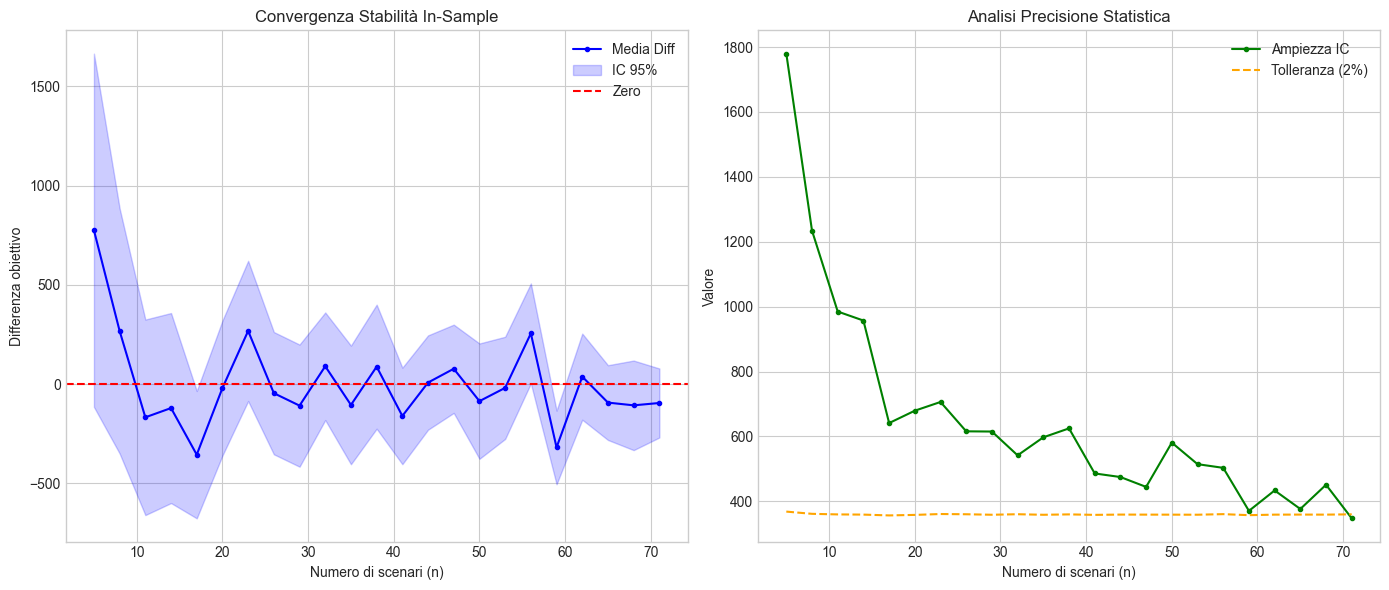

Stabilità in-sample raggiunta empiricamente per n = 71


In [149]:
#PARAMETRI 
sample_size = 5
sample_size_max = 200
N = 30                  # numero di coppie di replicazioni (S e S')
alpha = 0.05 
stabile = False

print(f"{'n':<5} | {'Media Diff':<12} | {'IC 95% Inf':<12} | {'IC 95% Sup':<12} | {'Ampiezza':<10} | {'Tolleranza':<10} | {'Stabile'}")
print("-" * 90)

n_values, means, lowers, uppers, ampiezze, tolleranze = [], [], [], [], [], []

while (not stabile) and (sample_size <= sample_size_max):
    phi_values = []
    profitti_assoluti = []
    
    for i in range(N):

        # Generazione Indipendente
        domanda_set_1 = genera_domande_per_scenario(sample_size)
        domanda_set_2 = genera_domande_per_scenario(sample_size)
        
        # Risoluzione
        res_1 = solve_bike_ato(domanda_set_1,pi, C, P, L, T, G, components, products, machines, scenarios, sample_size)
        res_2 = solve_bike_ato(domanda_set_2, pi, C, P, L, T, G, components, products, machines, scenarios, sample_size)
        
        diff = res_1["objective"] - res_2["objective"]
        phi_values.append(diff)
        profitti_assoluti.append(res_1["objective"])


    if len(phi_values) > 1:
        # Statistica descrittiva
        mean_diff = np.mean(phi_values)
        std_diff = np.std(phi_values, ddof=1)
        mean_profitto = np.mean(profitti_assoluti)
            
        if std_diff > 0:
            standard_error = std_diff / np.sqrt(len(phi_values))
            t_score = stats.t.ppf(1 - alpha/2, df=len(phi_values)-1)
            
            lower_bound = mean_diff - (t_score * standard_error)
            upper_bound = mean_diff + (t_score * standard_error)
        else:
            lower_bound = mean_diff
            upper_bound = mean_diff
        
        # CALCOLO AMPIEZZA E TOLLERANZA
        ampiezza_ic = upper_bound - lower_bound
        tolleranza = 0.01 * mean_profitto
        
        # CONDIZIONE DI STOP
        zero_in_range = (lower_bound <= 0 <= upper_bound)
        range_stretto = (ampiezza_ic <= tolleranza)
        stabile = zero_in_range and range_stretto

        n_values.append(sample_size)
        means.append(mean_diff)
        lowers.append(lower_bound)
        uppers.append(upper_bound)
        ampiezze.append(ampiezza_ic)
        tolleranze.append(tolleranza)
        
        print(f"{sample_size:<5} | {mean_diff:<12.2f} | {lower_bound:<12.2f} | {upper_bound:<12.2f} | {ampiezza_ic:<10.2f} | {tolleranza:<10.2f} | {stabile}")


    if not stabile:
        sample_size += 3
        sample_size_stability = sample_size
if n_values:
    plt.figure(figsize=(14, 6))

    # Grafico 1: Convergenza dell'IC
    plt.subplot(1, 2, 1)
    plt.plot(n_values, means, label="Media Diff", color='blue', marker='o', markersize=3)
    plt.fill_between(n_values, lowers, uppers, color='blue', alpha=0.2, label="IC 95%")
    plt.axhline(0, color='red', linestyle='--', label="Zero")
    plt.xlabel("Numero di scenari (n)")
    plt.ylabel("Differenza obiettivo")
    plt.title("Convergenza Stabilità In-Sample")
    plt.legend()
    plt.grid(True)

    # Grafico 2: Ampiezza vs Tolleranza
    plt.subplot(1, 2, 2)
    plt.plot(n_values, ampiezze, label="Ampiezza IC", color='green', marker='o', markersize=3)
    plt.plot(n_values, tolleranze, label="Tolleranza (2%)", color='orange', linestyle='--')
    plt.xlabel("Numero di scenari (n)")
    plt.ylabel("Valore")
    plt.title("Analisi Precisione Statistica")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

if stabile:
    print(f"Stabilità in-sample raggiunta empiricamente per n = {sample_size}")
else:
    print(f"Stabilità non raggiunta al limite di n = {sample_size_max}. È necessario un campione più ampio.")

# STABILITA' OUT-OF-SAMPLE
La stabilità out-of-sample valuta l'affidabilità di una decisione confrontando le sue prestazioni su due insiemi di scenari profondamente diversi per dimensioni. Nello specifico, dato un albero degli scenari utilizzato per calcolare la soluzione (che chiamiamo $\mathcal{S}$) e un secondo albero degli scenari di dimensione molto maggiore (che chiamiamo $\mathcal{E}$), l'obiettivo è verificare che i risultati siano coerenti tra loro. 

$$f(x^*|\mathcal{S}) \approx f(x^*|\mathcal{E})$$

La funzione *evaluate_out_of_sample* prende la soluzione x^* ottenuta dal modello in_sample e ottimizza le sole variabili del secondo stadio.

In [150]:
# STABILITA' OUT OF SAMPLE
def evaluate_out_of_sample(x_fixed, scenari_domanda_eval, pi, C, P, G, components, products, scenarios, sample_size):
 
    model = gp.Model("ATO_Out_Of_Sample_Evaluation")
    model.Params.OutputFlag = 0
    
    campioni = list(range(sample_size))

    y = model.addVars(products, scenarios, campioni, vtype=GRB.INTEGER, lb=0, name="y")

    # Funzione obiettivo
    ricavo_atteso = gp.quicksum(
        pi[s] * P[j] * (y[j, s, w] / sample_size)
        for j in products for s in scenarios for w in campioni
    )

    model.setObjective(ricavo_atteso, GRB.MAXIMIZE)

    
    # VINCOLI
    model.addConstrs(
        (y[j, s, w] <= scenari_domanda_eval[j][s][w] for j in products for s in scenarios for w in campioni),
        name="Domanda"
    )

    model.addConstrs(
        (gp.quicksum(G[i][j] * y[j, s, w] for j in products) <= x_fixed[i] for i in components for s in scenarios for w in campioni),
        name="Disponibilita_Fissa"
    )

    model.optimize()

    if model.Status == GRB.OPTIMAL:
        costo_fisso = sum(C[i] * x_fixed[i] for i in components)
        # Calcoliamo i profitti per ogni scenario (s) e campione (w)
        lista_profitti = []
        for s in scenarios:
            for w in range(sample_size):
                ricavo_scenario = sum(P[j] * y[j, s, w].X for j in products)
                lista_profitti.append(ricavo_scenario - costo_fisso)
        
        profitto_out_of_sample = model.ObjVal - costo_fisso
        return profitto_out_of_sample, lista_profitti
    return None, None

In [151]:
N_out_of_sample = [100, 250, 400, 500, 750, 1000, 5000, 10000, 50000]
print(f"Inizio analisi...")
domanda_S = genera_domande_per_scenario(sample_size_stability)

# Calcolo della soluzione x*
risultato_S = solve_bike_ato(domanda_S, pi, C, P, L, T, G, components, products, machines, scenarios, sample_size_stability)
profitto_in_sample = risultato_S["objective"]  # f(x*|S)
x_ottimo = risultato_S["x"]                    # x*


# Ciclo di valutazione Out-of-Sample
print(f"\n{'N':<6} | {'Profitto OOS':<15} | {'Gap Assoluto':<15} | {'Gap %':<10} |  {'Superato'}")
print("-" * 60)

risultati_list = []

for N in N_out_of_sample:
    # campione di dimensione N
    domanda_E = genera_domande_per_scenario(N)

    # VALUATE OUT-OF-SAMPLE
    profitto_out_of_sample, lista_profitti_E = evaluate_out_of_sample(x_ottimo, domanda_E, pi, C, P, G, components, products, scenarios, N) # f(x*|E)

    gap_assoluto = abs(profitto_in_sample - profitto_out_of_sample)
    gap_percentuale = (gap_assoluto / abs(profitto_in_sample)) * 100

    # Valutazione logica
    stato_test = "TRUE" if gap_percentuale < 1.5 else "FALSE"

    risultati_list.append({
        "N": N,
        "Profitto_OOS": profitto_out_of_sample,
        "Gap_Percentuale": gap_percentuale,
        "Superato": superato
    })

    print(f"{N:<6} | € {profitto_out_of_sample:<12,.2f} | € {gap_assoluto:<12,.2f} | {gap_percentuale:<9.3f} | {stato_test}")


Inizio analisi...

N      | Profitto OOS    | Gap Assoluto    | Gap %      |  Superato
------------------------------------------------------------
100    | € 35,513.64    | € 10.31        | 0.029     | TRUE
250    | € 35,815.94    | € 312.61       | 0.880     | TRUE
400    | € 35,740.06    | € 236.73       | 0.667     | TRUE
500    | € 35,861.52    | € 358.19       | 1.009     | TRUE
750    | € 35,633.33    | € 130.00       | 0.366     | TRUE
1000   | € 35,700.17    | € 196.84       | 0.554     | TRUE
5000   | € 35,820.73    | € 317.40       | 0.894     | TRUE
10000  | € 35,874.40    | € 371.07       | 1.045     | TRUE
50000  | € 35,836.31    | € 332.98       | 0.938     | TRUE


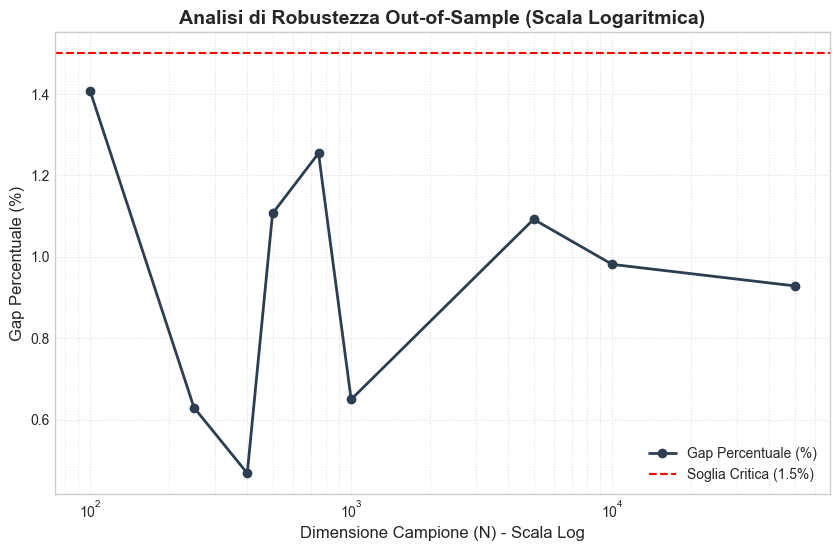

In [152]:
# GRAFICO OUT-OF SAMPLE
import pandas as pd
plt.figure(figsize=(10, 6))

# Plot dei dati
plt.plot(df_risultati['N'], df_risultati['Gap_Percentuale'], 
         marker='o', linestyle='-', color='#2C3E50', linewidth=2, label='Gap Percentuale (%)')

plt.xscale('log') 
plt.axhline(y=1.5, color='red', linestyle='--', linewidth=1.5, label='Soglia Critica (1.5%)')

plt.title('Analisi di Robustezza Out-of-Sample (Scala Logaritmica)', fontsize=14, fontweight='bold')
plt.xlabel('Dimensione Campione (N) - Scala Log', fontsize=12)
plt.ylabel('Gap Percentuale (%)', fontsize=12)
plt.grid(True, which="both", linestyle=':', alpha=0.6) # 'which=both' serve per la scala log
plt.legend()
plt.show()

# ANALISI VSS 
$$VSS = EEV - RP$$
rappresenta il valore che si ottiene risolvendo il problema stocastico rispetto al problema deterministico basato sul valore atteso. Per definizione, essendo un "valore", il VSS deve essere una quantità non negativa ($VSS \ge 0$).

si risolve il problema per ottenere il profitto ottimo: 
$$RP = \max_{x} \left\{ f(x) + \mathbb{E}_{\xi} [Q(x, \xi)] \right\}$$

Chiamiamo Expected Value Solution: 
$$ \bar{x} \in argmin f_1(x) + f_2(x, \mathbb{E}_{\epsilon} [\epsilon]) $$
dove si considera il valore atteso dell'incertezza (la domanda) quindi scrivo il modello in questo caso in cui si considera il valore medio.


Per implementare i vari problemi di ottimizzazione dividiamo il codice in più funzioni: 
- expected_demand_from_samples: calcola la domanda attesa del problema EV
- solve_ev_problem: risolve il modello deterministico usando la domanda media E[D].
- evaluate_fixed_first_stage_solution : Fissa le decisioni di primo stadio ($x$) e ottimizza solo il secondo stadio ($y$) per ogni scenario, simulando cosa accadrebbe nel mondo reale se seguissi il piano "medio" senza considerare la variabilità.
- compute_vss: Unisce tutto e calcola VSS

In [153]:
#UTILS

def expected_demand_from_samples(d, pi, products, scenarios):
    """
    Calcola la domanda attesa del problema EV.
    """
    return {
        j: sum(pi[s] * float(np.mean(d[j][s])) for s in scenarios)
        for j in products
    }

def solve_ev_problem(d_mean, C, P, L, T, G, components, products, machines):
    """
    Expected Value Problem:
    risolve il modello deterministico usando la domanda media E[D].
    Restituisce la soluzione di primo stadio x_EV.
    """
    m_ev = gp.Model("EV_Model")
    m_ev.Params.OutputFlag = 0

    x = m_ev.addVars(components, vtype=GRB.INTEGER, lb=0, name="x_EV")
    y = m_ev.addVars(products,   vtype=GRB.INTEGER, lb=0, name="y_EV")

    costo = gp.quicksum(C[i] * x[i] for i in components)
    ricavo = gp.quicksum(P[j] * y[j] for j in products)
    m_ev.setObjective(ricavo - costo, GRB.MAXIMIZE)

    # VINCOLI
    for m in machines:
        m_ev.addConstr(
            gp.quicksum(T[i][m] * x[i] for i in components) <= L[m],
            name=f"Capacita_{m}"
        )

    for j in products:
        m_ev.addConstr(y[j] <= d_mean[j], name=f"Domanda_media_{j}")

    for i in components:
        m_ev.addConstr(
            gp.quicksum(G[i][j] * y[j] for j in products) <= x[i],
            name=f"Disponibilita_{i}"
        )

    m_ev.optimize()

    if m_ev.Status == GRB.OPTIMAL:
        return {
            "objective_EV": m_ev.ObjVal,
            "x": {i: x[i].X for i in components},
            "y": {j: y[j].X for j in products},
            "model": m_ev
        }
    else:
        return None



def evaluate_fixed_first_stage_solution(x_fixed, d_eval, pi, C, P, G, components, products, scenarios):
    """
    Calcola EEV:
    valuta una soluzione di primo stadio fissata x_fixed sugli sceanri reali che si realizzano.
    Qui si ottimizza solo il secondo stadio y[j,s,w].
    """

    # ricavo numero di sample_size
    sample_size = len(next(iter(next(iter(d_eval.values())).values())))
    campioni = range(sample_size)

    m = gp.Model("Evaluate_Fixed_x_EEV")
    m.Params.OutputFlag = 0

    # variabili del secondo stadio
    y = m.addVars(products, scenarios, campioni, vtype=GRB.INTEGER, lb=0, name="y_eval")

    ricavo_atteso = gp.quicksum(
        pi[s] * (1.0 / sample_size) * P[j] * y[j, s, w]
        for j in products
        for s in scenarios
        for w in campioni
    )

    costo_fisso = sum(C[i] * x_fixed[i] for i in components)
    m.setObjective(ricavo_atteso - costo_fisso, GRB.MAXIMIZE)

    # VINCOLI (con x_fixed)
    for j in products:
        for s in scenarios:
            for w in campioni:
                m.addConstr(
                    y[j, s, w] <= d_eval[j][s][w],
                    name=f"Domanda_{j}_{s}_{w}"
                )

    for i in components:
        for s in scenarios:
            for w in campioni:
                m.addConstr(
                    gp.quicksum(G[i][j] * y[j, s, w] for j in products) <= x_fixed[i],
                    name=f"Disponibilita_fissa_{i}_{s}_{w}"
                )

    m.optimize()

    if m.Status == GRB.OPTIMAL:
        return {
            "objective": m.ObjVal,
            "y": {(j, s, w): y[j, s, w].X for j in products for s in scenarios for w in campioni},
            "model": m
        }
    else:
        return None
    


def compute_vss(sample_size_vss, seed=set_seed):
    """
    Calcola RP, EV, EEV e VSS.
    Per un problema di MASSIMIZZAZIONE del profitto:
        VSS  = RP - EEV
    """
    # controllo riproducibilità
    np.random.seed(seed)

    # generazione delle domande per entrambi i problemi per garantire un confronto valido
    d_stoch = genera_domande_per_scenario(sample_size_vss)

    # RP modello stocastico
    rp_res = solve_bike_ato(d_stoch, pi, C, P, L, T, G, components, products, machines, scenarios, sample_size_vss)
    RP = rp_res["objective"]
    x_RP = rp_res["x"]

    # EV modello deterministico sulla domanda media
    d_mean = expected_demand_from_samples(d_stoch, pi, products, scenarios)
    ev_res = solve_ev_problem(d_mean, C, P, L, T, G, components, products, machines)
    x_EV = ev_res["x"]

    # EEV: valuto x_EV sugli stessi campioni del modello stocastico
    eev_res = evaluate_fixed_first_stage_solution(x_EV, d_stoch, pi, C, P, G, components, products, scenarios)
    EEV = eev_res["objective"]

    # Calcolo VSS
    VSS = RP - EEV

    results = {
        "sample_size": sample_size_vss,
        "RP": RP,
        "EV_objective": ev_res["objective_EV"],
        "EEV": EEV,
        "VSS": VSS,
        "x_RP": x_RP,
        "x_EV": x_EV,
        "d_mean": d_mean,
        "d_stoch": d_stoch
    }

    return results

N_values = list(range(100, 2100, 100))
vss_history = []

print(f"{'N':<8} | {'RP':<12} | {'EEV':<12} | {'VSS':<12}")
print("-" * 50)

# ESECUZIONE
for n in N_values:
    vss_results = compute_vss(n, seed=set_seed)
    vss_history.append({"N": n, **vss_results})

    print(f"{n:<8} | {vss_results['RP']:<12.2f} | {vss_results['EEV']:<12.2f} | {vss_results['VSS']:<12.2f}")

# Variabile globale ultima iterazione
d_stoch = vss_results["d_stoch"]
d_mean = vss_results["d_mean"]
RP = vss_results["RP"]
EEV = vss_results["EEV"]
VSS = vss_results["VSS"]
x_RP = vss_results["x_RP"]
x_EV = vss_results["x_EV"]
EV = vss_results["EV_objective"]



N        | RP           | EEV          | VSS         
--------------------------------------------------
100      | 35973.67     | 30245.11     | 5728.56     
200      | 36177.60     | 30132.65     | 6044.95     
300      | 35771.73     | 29810.26     | 5961.48     
400      | 35919.68     | 29846.24     | 6073.44     
500      | 36102.02     | 30882.70     | 5219.32     
600      | 35622.78     | 29940.21     | 5682.57     
700      | 35899.12     | 29952.92     | 5946.20     
800      | 35951.17     | 29941.09     | 6010.09     
900      | 36024.98     | 30624.32     | 5400.66     
1000     | 36111.62     | 30542.61     | 5569.01     
1100     | 35798.63     | 29654.85     | 6143.78     
1200     | 35843.38     | 30178.38     | 5664.99     
1300     | 35908.30     | 30120.77     | 5787.54     
1400     | 35927.68     | 30236.33     | 5691.35     
1500     | 35903.16     | 30383.66     | 5519.49     
1600     | 36042.27     | 30336.21     | 5706.06     
1700     | 36029.76     | 30154

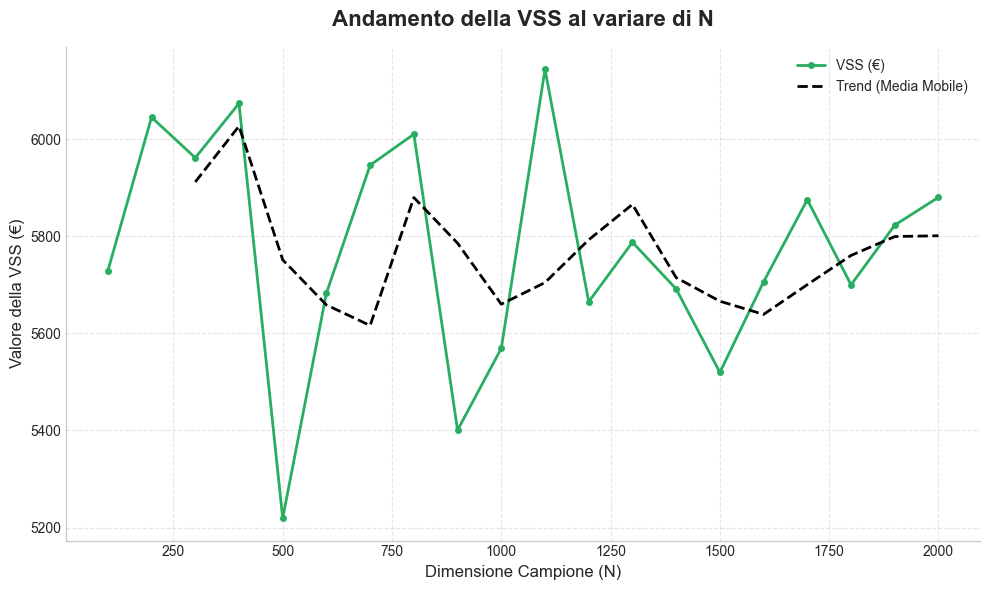

In [154]:
# GAFICO VSS
df_vss = pd.DataFrame(vss_history)

plt.figure(figsize=(10, 6))

plt.plot(df_vss['N'], df_vss['VSS'], 
         linestyle='-', 
         color='#27AE60', 
         linewidth=2, 
         marker='o', 
         markersize=4, 
         label='VSS (€)')

df_vss['Trend'] = df_vss['VSS'].rolling(window=3).mean()
plt.plot(df_vss['N'], df_vss['Trend'], 
         color='black', 
         linewidth=2, 
         linestyle='--', 
         label='Trend (Media Mobile)')

plt.title('Andamento della VSS al variare di N', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Dimensione Campione (N)', fontsize=12)
plt.ylabel('Valore della VSS (€)', fontsize=12)
plt.grid(True, which='major', linestyle='--', alpha=0.5)

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.legend(frameon=False)
plt.tight_layout()
plt.show()

# ANALISI EVPI 
L'EVPI confronta il nostro modello stocastico ($RP$) con una situazione ideale in cui possediamo l'informazione perfetta ($WS$).  Pertanto misura il limite massimo di profitto teoricamente ottenibile se si disponesse di informazioni perfette sulla domanda prima di ogni decisione.
$$EVPI = WS - RP$$
dove: 
$$WS = \mathbb{E}_{\xi}[z(\overline{x}(\xi),\xi)]$$
dove la decisione di primo stadio $\overline{x}(\xi)$ dipende direttamente dallo specifico scenario $\xi$ che si verificherà. 

Il codice sviluppa il calcolo di EVPI tramite le funzioni: 
- solve_wait_and_see_single_demand: costruisce e risolve un modello di ottimizzazione per quel dato valore di domanda. Rappresenta quindi il comportamento di un "oracolo" che conosce il futuro. 
- compute_ws_value: Aggrega i risultati della funzione precedente su tutti gli scenari e campioni. Calcola il WS (Wait-and-See), ovvero il limite teorico superiore di profitto. 
- compute_evpi: mette insieme il tutto per il calcolo dell'indicatore EVPI

In [155]:
def solve_wait_and_see_single_demand(demand_single, C, P, L, T, G, components, products, machines):
    """
    Modello deterministico con informazione perfetta per UNA realizzazione della domanda.
    """
    m = gp.Model("WS_single_realization")
    m.Params.OutputFlag = 0

    x = m.addVars(components, vtype=GRB.INTEGER, lb=0, name="x_WS")
    y = m.addVars(products,   vtype=GRB.INTEGER, lb=0, name="y_WS")

    costo = gp.quicksum(C[i] * x[i] for i in components)
    ricavo = gp.quicksum(P[j] * y[j] for j in products)
    m.setObjective(ricavo - costo, GRB.MAXIMIZE)

    for mac in machines:
        m.addConstr(
            gp.quicksum(T[i][mac] * x[i] for i in components) <= L[mac],
            name=f"Capacita_{m}"
        )

    for j in products:
        m.addConstr(y[j] <= demand_single[j], name=f"Domanda_{j}")

    for i in components:
        m.addConstr(
            gp.quicksum(G[i][j] * y[j] for j in products) <= x[i],
            name=f"Disponibilita_{i}"
        )

    m.optimize()
    
    # Controllo di ottimalità 
    if m.Status == GRB.OPTIMAL:
        return m.ObjVal
    else:
        return None



def compute_ws_value(d_eval, pi, C, P, L, T, G, components, products, machines, scenarios):
    """
    WS = valore atteso con informazione perfetta.
    Risolve un problema deterministico per ogni coppia (scenario, campione) 
    e ne calcola la media ponderata.
    """
    sample_size = len(next(iter(next(iter(d_eval.values())).values())))
    WS = 0.0

    for s in scenarios:
        for w in range(sample_size):
            # Isoliamo la domanda esatta di quel singolo futuro
            demand_single = {j: d_eval[j][s][w] for j in products}
            
            # Calcoliamo il profitto perfetto per quel futuro
            obj_sw = solve_wait_and_see_single_demand(
                demand_single, C, P, L, T, G, components, products, machines
            )
            
            # Ponderiamo per la probabilità dello scenario e la media campionaria
            WS += pi[s] * (1.0 / sample_size) * obj_sw

    return WS


def compute_evpi(sample_size_evpi, seed=set_seed):
    """
    Calcola RP, WS e EVPI.
    Per un problema di MASSIMIZZAZIONE del profitto: EVPI = WS - RP
    """
    np.random.seed(seed)

    # generazione delle domande per entrambi i problemi per garantire un confronto valido
    d_stoch = genera_domande_per_scenario(sample_size_evpi)

    # RP modello stocastico
    rp_res = solve_bike_ato(d_stoch, pi, C, P, L, T, G, components, products, machines, scenarios, sample_size_evpi)
    RP = rp_res["objective"]

    # WS modello con informazione perfetta (Wait-and-See)
    WS = compute_ws_value(d_stoch, pi, C, P, L, T, G, components, products, machines, scenarios)

    # Calcolo EVPI
    EVPI = WS - RP

    results = {
        "sample_size": sample_size_evpi,
        "RP": RP,
        "WS": WS,
        "EVPI": EVPI,
        "d_stoch": d_stoch
    }

    return results

N_values = list(range(100, 2100, 100))
evpi_history = []

print(f"{'N':<8} | {'WS':<12} | {'RP':<12} | {'EVPI':<12}")
print("-" * 50)

for n in N_values:
    # ESECUZIONE
    evpi_results = compute_evpi(n, seed=set_seed)
    evpi_history.append({"N": n, **evpi_results})

    print(f"{n:<8} | {evpi_results['WS']:<12.2f} | {evpi_results['RP']:<12.2f} | {evpi_results['EVPI']:<12.2f}")


# Salvtaggio variabili globali
RP = evpi_results["RP"]
WS = evpi_results["WS"]
EVPI = evpi_results["EVPI"]
d_stoch = evpi_results["d_stoch"]


N        | WS           | RP           | EVPI        
--------------------------------------------------
100      | 44241.33     | 35973.67     | 8267.66     
200      | 44240.47     | 36177.60     | 8062.87     
300      | 44214.25     | 35771.73     | 8442.52     
400      | 44214.78     | 35919.68     | 8295.10     
500      | 44302.37     | 36102.02     | 8200.35     
600      | 44221.16     | 35622.78     | 8598.38     
700      | 44226.27     | 35899.12     | 8327.16     
800      | 44224.52     | 35951.17     | 8273.35     
900      | 44281.63     | 36024.98     | 8256.65     
1000     | 44273.46     | 36111.62     | 8161.84     
1100     | 44199.06     | 35798.63     | 8400.43     
1200     | 44242.68     | 35843.38     | 8399.30     
1300     | 44239.89     | 35908.30     | 8331.59     
1400     | 44247.65     | 35927.68     | 8319.97     
1500     | 44259.41     | 35903.16     | 8356.26     
1600     | 44255.83     | 36042.27     | 8213.56     
1700     | 44242.18     | 36029

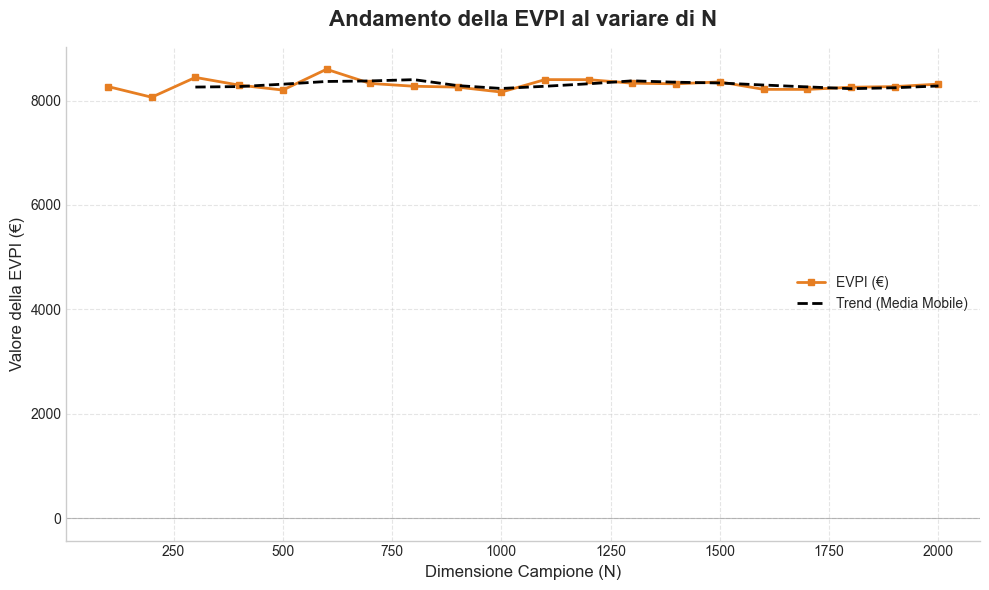

In [156]:
#GRAFICO EVPI
df_evpi = pd.DataFrame(evpi_history)

plt.figure(figsize=(10, 6))

# Plot dei dati EVPI
plt.plot(df_evpi['N'], df_evpi['EVPI'], 
         linestyle='-', 
         color='#E67E22', 
         linewidth=2, 
         marker='s', 
         markersize=4, 
         label='EVPI (€)')

df_evpi['Trend'] = df_evpi['EVPI'].rolling(window=3).mean()
plt.plot(df_evpi['N'], df_evpi['Trend'], 
         color='black', 
         linewidth=2, 
         linestyle='--', 
         label='Trend (Media Mobile)')

plt.title('Andamento della EVPI al variare di N', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Dimensione Campione (N)', fontsize=12)
plt.ylabel('Valore della EVPI (€)', fontsize=12)
plt.axhline(0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5) # Linea dello zero
plt.grid(True, which='major', linestyle='--', alpha=0.5)

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.legend(frameon=False)
plt.tight_layout()
plt.show()

verifica correttezza per le variabili globali salvate (ultima iterazione)
per un problema di massimo
$$WS \ge RP \ge EEV$$

In [157]:
print("--- VERIFICA TEORICA: PROBLEMA DI MASSIMO ---")
if WS >= RP and RP >= EEV:
    print(" SUCCESSO: La condizione WS >= RP >= EEV è rispettata.")
    print(f" Dettaglio: {WS:.2f} >= {RP:.2f} >= {EEV:.2f}")
else:
    print(" ERRORE: I risultati NON rispettano la gerarchia teorica.")
    print(f" Dettaglio: WS={WS:.2f}, RP={RP:.2f}, EEV={EEV:.2f}")

--- VERIFICA TEORICA: PROBLEMA DI MASSIMO ---
 SUCCESSO: La condizione WS >= RP >= EEV è rispettata.
 Dettaglio: 44231.19 >= 35916.78 >= 30036.68


<>:10: SyntaxWarning: invalid escape sequence '\g'
<>:10: SyntaxWarning: invalid escape sequence '\g'
C:\Users\beagn\AppData\Local\Temp\ipykernel_26480\918824940.py:10: SyntaxWarning: invalid escape sequence '\g'
  plt.title('Verifica Gerarchia: WS $\geq$ RP $\geq$ EEV', fontsize=16, fontweight='bold', pad=15)


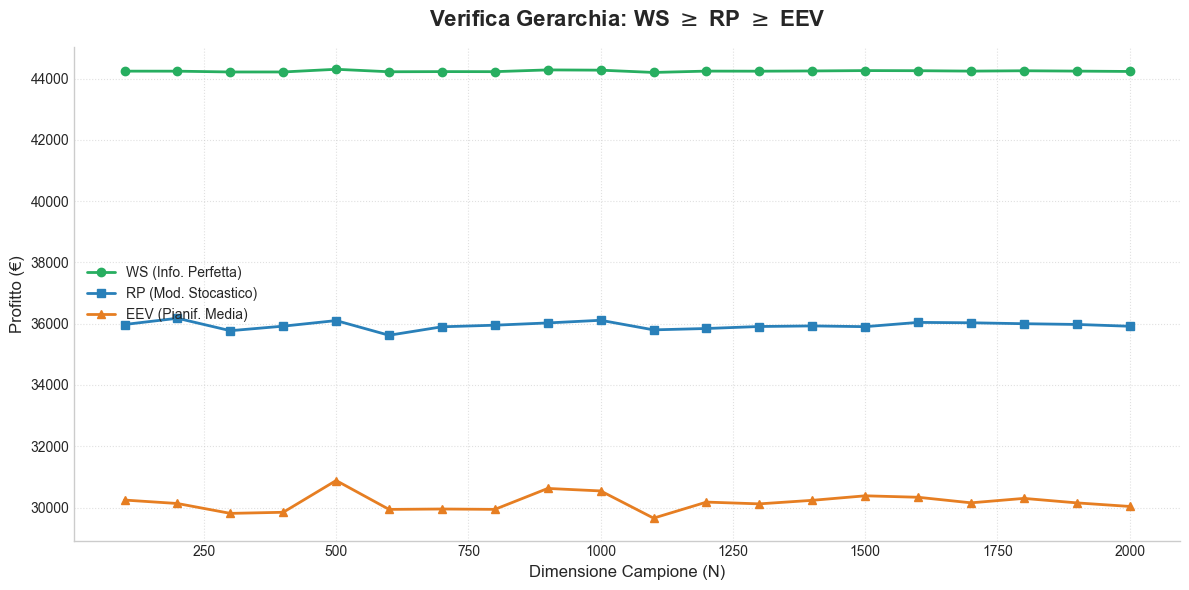

In [158]:
#GRAFICO VERIFICA PER OGNI DIMENSIONE 
df_gerarchia = pd.merge(df_vss[['N', 'RP', 'EEV']], df_evpi[['N', 'WS']], on='N')

plt.figure(figsize=(12, 6))

plt.plot(df_gerarchia['N'], df_gerarchia['WS'],  marker='o', color='#27AE60', label='WS (Info. Perfetta)', linewidth=2)
plt.plot(df_gerarchia['N'], df_gerarchia['RP'],  marker='s', color='#2980B9', label='RP (Mod. Stocastico)', linewidth=2)
plt.plot(df_gerarchia['N'], df_gerarchia['EEV'], marker='^', color='#E67E22', label='EEV (Pianif. Media)', linewidth=2)

plt.title('Verifica Gerarchia: WS $\geq$ RP $\geq$ EEV', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Dimensione Campione (N)', fontsize=12)
plt.ylabel('Profitto (€)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=False)

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# STUDIO DELLA ROBUSTEZZA
Un modello solido non deve solo massimizzare il profitto sotto condizioni ideali, ma deve dimostrarsi resiliente a fronte di errori di stima nei parametri o scostamenti nella forma distributiva. Gli 'indicatori chiave su cui si basa sono:
1)  il *regret* cioè la differenza tra il profitto che avresti potuto ottenere (ottimo vero) e quello che hai ottenuto con la tua scelta (basata su assunzioni errate). Se il Regret è alto, il modello non è robusto: è troppo rigido o troppo dipendente da assunzioni fragili.
2) la distanza *x* Misura quanto le tue decisioni di primo stadio ($x_{assunta}$) siano fisicamente lontane da quelle ideali ($x_{vera}$). 


In [159]:
# FUNZIONI DI SUPPORTO - ROBUSTEZZA

def genera_domande_parametri_diversi(sample_size, moltiplicatore_media=1.0, moltiplicatore_std=1.0):
    """
    Stessa struttura della domanda del caso base, ma con medie e deviazioni standard modificate.
    """
    # s1: alta domanda - lognormale
    mu_s1_j1, sig_s1_j1 = target_to_lognormal(300 * moltiplicatore_media, 45 * moltiplicatore_std)
    mu_s1_j2, sig_s1_j2 = target_to_lognormal(200 * moltiplicatore_media, 30 * moltiplicatore_std)
    mu_s1_j3, sig_s1_j3 = target_to_lognormal(150 * moltiplicatore_media, 25 * moltiplicatore_std)

    d_s1_j1 = np.round(np.random.lognormal(mu_s1_j1, sig_s1_j1, sample_size)).astype(int)
    d_s1_j2 = np.round(np.random.lognormal(mu_s1_j2, sig_s1_j2, sample_size)).astype(int)
    d_s1_j3 = np.round(np.random.lognormal(mu_s1_j3, sig_s1_j3, sample_size)).astype(int)

    # s2: domanda media - normale troncata
    d_s2_j1 = np.round(np.maximum(0, np.random.normal(225 * moltiplicatore_media, 20 * moltiplicatore_std, sample_size))).astype(int)
    d_s2_j2 = np.round(np.maximum(0, np.random.normal(140 * moltiplicatore_media, 15 * moltiplicatore_std, sample_size))).astype(int)
    d_s2_j3 = np.round(np.maximum(0, np.random.normal(100 * moltiplicatore_media, 10 * moltiplicatore_std, sample_size))).astype(int)

    # s3: bassa domanda - lognormale
    mu_s3_j1, sig_s3_j1 = target_to_lognormal(150 * moltiplicatore_media, 30 * moltiplicatore_std)
    mu_s3_j2, sig_s3_j2 = target_to_lognormal(80 * moltiplicatore_media, 20 * moltiplicatore_std)
    mu_s3_j3, sig_s3_j3 = target_to_lognormal(50 * moltiplicatore_media, 15 * moltiplicatore_std)

    d_s3_j1 = np.round(np.random.lognormal(mu_s3_j1, sig_s3_j1, sample_size)).astype(int)
    d_s3_j2 = np.round(np.random.lognormal(mu_s3_j2, sig_s3_j2, sample_size)).astype(int)
    d_s3_j3 = np.round(np.random.lognormal(mu_s3_j3, sig_s3_j3, sample_size)).astype(int)

    d = {
        'j1': {'s1': d_s1_j1.tolist(), 's2': d_s2_j1.tolist(), 's3': d_s3_j1.tolist()},
        'j2': {'s1': d_s1_j2.tolist(), 's2': d_s2_j2.tolist(), 's3': d_s3_j2.tolist()},
        'j3': {'s1': d_s1_j3.tolist(), 's2': d_s2_j3.tolist(), 's3': d_s3_j3.tolist()}
    }

    return d



def genera_domande_distribuzione_diversa(sample_size, tipo_distribuzione):
    """
    Genera domanda con una forma distributiva diversa da quella assunta nel caso base.
    """

    medie = {
        'j1': {'s1': 300, 's2': 225, 's3': 150},
        'j2': {'s1': 200, 's2': 140, 's3': 80},
        'j3': {'s1': 150, 's2': 100, 's3': 50}
    }

    std = {
        'j1': {'s1': 45, 's2': 20, 's3': 30},
        'j2': {'s1': 30, 's2': 15, 's3': 20},
        'j3': {'s1': 25, 's2': 10, 's3': 15}
    }

    d = {}

    for j in products:
        d[j] = {}

        for s in scenarios:

            media = medie[j][s]
            deviazione = std[j][s]

            if tipo_distribuzione == "normale":
                valori = np.maximum(0, np.random.normal(media, deviazione, sample_size))

            elif tipo_distribuzione == "poisson":
                valori = np.random.poisson(media, sample_size)

            elif tipo_distribuzione == "gamma":
                shape = (media / deviazione) ** 2
                scale = (deviazione ** 2) / media
                valori = np.random.gamma(shape, scale, sample_size)

            elif tipo_distribuzione == "mistura":
                p_successo = 0.20

                successo = np.random.binomial(1, p_successo, sample_size)

                domanda_alta = np.random.normal(1.35 * media, 1.20 * deviazione, sample_size)
                domanda_bassa = np.random.normal(0.90 * media, 0.80 * deviazione, sample_size)

                valori = successo * domanda_alta + (1 - successo) * domanda_bassa
                valori = np.maximum(0, valori)

            else:
                raise ValueError("Distribuzione non riconosciuta")

            d[j][s] = np.round(valori).astype(int).tolist()

    return d


def valuta_robustezza(domanda_assunta, domanda_vera, pi_assunta, pi_vera, sample_size):
    """
    Confronta:
    - soluzione ottimizzata sulla distribuzione assunta;
    - stessa soluzione valutata sulla distribuzione vera;
    - soluzione ottima conoscendo la distribuzione vera.
    """

    # Ottimizzo usando la distribuzione assunta
    res_assunta = solve_bike_ato( domanda_assunta, pi_assunta, C, P, L, T, G, components, products, machines, scenarios, sample_size)

    x_assunta = res_assunta["x"]
    profitto_assunto = res_assunta["objective"]

    # Valuto la x assunta sulla distribuzione vera
    eval_vera = evaluate_fixed_first_stage_solution( x_assunta, domanda_vera, pi_vera, C, P, G,components, products, scenarios)
    profitto_x_su_vero = eval_vera["objective"]

    # Ottimo che si avrebbe conoscendo la distribuzione vera
    res_vera = solve_bike_ato( domanda_vera, pi_vera, C, P, L, T, G, components, products, machines, scenarios, sample_size)
    profitto_ottimo_vero = res_vera["objective"]
    x_vera = res_vera["x"]

    # Indicatori
    regret = profitto_ottimo_vero - profitto_x_su_vero
    regret_percentuale = 100 * regret / abs(profitto_ottimo_vero)

    distanza_x = np.mean([abs(x_assunta[i] - x_vera[i]) for i in components])

    return {
        "profitto_assunto": profitto_assunto,
        "profitto_x_su_vero": profitto_x_su_vero,
        "profitto_ottimo_vero": profitto_ottimo_vero,
        "regret": regret,
        "regret_percentuale": regret_percentuale,
        "distanza_x": distanza_x
    }

Verifichiamo la robustezza tramite due analisi:
### ANALISI 1: Variazione dei parametri 
La capacità di un modello di ottimizzazione di generare risultati affidabili dipende intrinsecamente dalla qualità dei dati in input. Tuttavia, in un contesto di mercato dinamico, le stime su media e variabilità della domanda sono soggette a margini di errore. L'obiettivo primario è identificare il perimetro di stabilità della strategia operativa entro il quale la configurazione ottimale delle scorte di componenti ($x$) si adatta a perturbazioni sistematiche della domanda. 
La variazione consiste in:   
1) **Perturbazioni Parametriche (Bias di Media)**: Identifica se il modello è "sotto-dimensionato" (rischio di stock-out) o "sovra-dimensionato" (rischio di capitale immobilizzato).
2) **Perturbazioni di Volatilità (Dispersione)**: Definisce la capacità del sistema di gestire la "rumorosità" del mercato. 
3) **Perturbazioni di Configurazione dello Scenario (Probabilità)**: Testa la resilienza della strategia $x$ rispetto a cambiamenti strutturali del contesto economico.



In [160]:
# ROBUSTEZZA - PARAMETRI DIVERSI
import pandas as pd
dimensioni_campione = list(range(100, 1100, 100))

# lista delle modifiche
casi_parametri = [
    ("Domanda vera +10%", 1.10, 1.00, pi),      # shift della domanda +10
    ("Domanda vera -10%", 0.90, 1.00, pi),      # shift della domanda -10
    ("Volatilita vera +25%", 1.00, 1.25, pi),   # shift della volatilità +25
    ("Volatilita vera -25%", 1.00, 0.75, pi),   # shift della volatilità -25
    ("Bassa domanda piu probabile (mercato in crisi)", 1.00, 1.00, {'s1': 0.10, 's2': 0.25, 's3': 0.65}),       # cambio probabilità degli scenari (mercato in crisi)
    ("Alta domanda piu probabile (mercato in crisi)", 1.00, 1.00, {'s1': 0.50, 's2': 0.35, 's3': 0.15}),       # cambio probabilità degli scenari (mercato in crisi)
    ("Domanda +10% e volatilita +25%", 1.10, 1.25, pi)  # combinato domanda e volatilià
]

risultati_parametri = []
data_parametri_per_grafico = []

for N_val in dimensioni_campione:
    # Intestazione tabellare per ogni N
    print(f"\n+" + "-" * 88 + "+")
    print(f"| ESECUZIONE TEST PARAMETRICI CON N = {N_val:<50} |")
    print("+" + "-" * 88 + "+")
    print(f"| {'CASO ANALIZZATO':<50} | {'REGRET %':<15} | {'DISTANZA X':<15} |")
    print("+" + "-" * 88 + "+")

    for nome_caso, mult_media, mult_std, pi_vera in casi_parametri:

            np.random.seed(set_seed)
                        
            # Generazione dati coerenti con N_val
            domanda_assunta = genera_domande_per_scenario(N_val)
            domanda_vera = genera_domande_parametri_diversi(
                sample_size=N_val,
                moltiplicatore_media=mult_media,
                moltiplicatore_std=mult_std
            )
            
            risultato = valuta_robustezza(
                domanda_assunta=domanda_assunta,
                domanda_vera=domanda_vera,
                pi_assunta=pi,
                pi_vera=pi_vera,
                sample_size=N_val
            )
            
            # Salvataggio per analisi successiva (grafici)
            risultati_parametri.append((f"{nome_caso}_N{N_val}", risultato))
            data_parametri_per_grafico.append({
                "Caso": nome_caso,
                "N": N_val,
                "Regret_Percentuale": risultato['regret_percentuale'],
                "Distanza_X": risultato['distanza_x'],
                "Profitto_Assunto": risultato['profitto_assunto'],
                "Profitto_Reale": risultato['profitto_x_su_vero'],
                "Profitto_Ottimo": risultato['profitto_ottimo_vero']
            })
            # Stampa allineata della riga
            print(f"| {nome_caso:<50} | {risultato['regret_percentuale']:>14.3f}% | {risultato['distanza_x']:>15.2f} |")
            
    # Chiusura tabella per N corrente
    print("+" + "-" * 88 + "+")
    
# Trasformazione in DataFrame per grafici facili
df_parametri = pd.DataFrame(data_parametri_per_grafico)


+----------------------------------------------------------------------------------------+
| ESECUZIONE TEST PARAMETRICI CON N = 100                                                |
+----------------------------------------------------------------------------------------+
| CASO ANALIZZATO                                    | REGRET %        | DISTANZA X      |
+----------------------------------------------------------------------------------------+
| Domanda vera +10%                                  |          0.464% |            6.07 |
| Domanda vera -10%                                  |          0.145% |            2.20 |
| Volatilita vera +25%                               |          0.000% |            0.00 |
| Volatilita vera -25%                               |          0.000% |            0.00 |
| Bassa domanda piu probabile (mercato in crisi)     |          5.387% |            5.87 |
| Alta domanda piu probabile (mercato in crisi)      |          0.344% |            7.53 

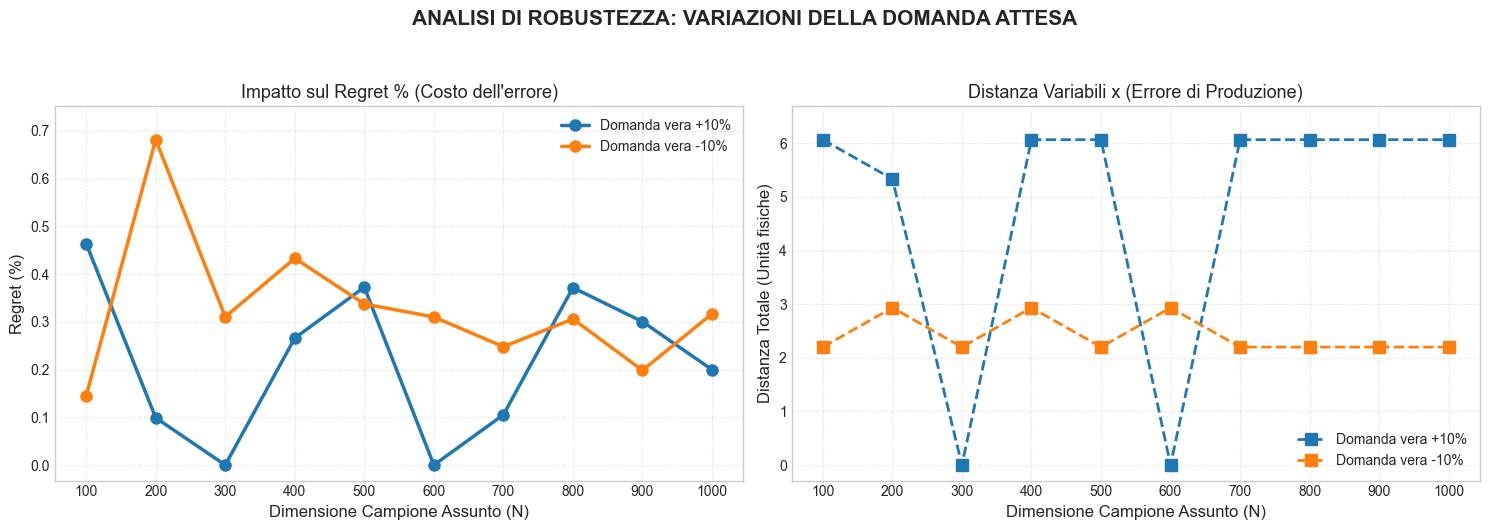

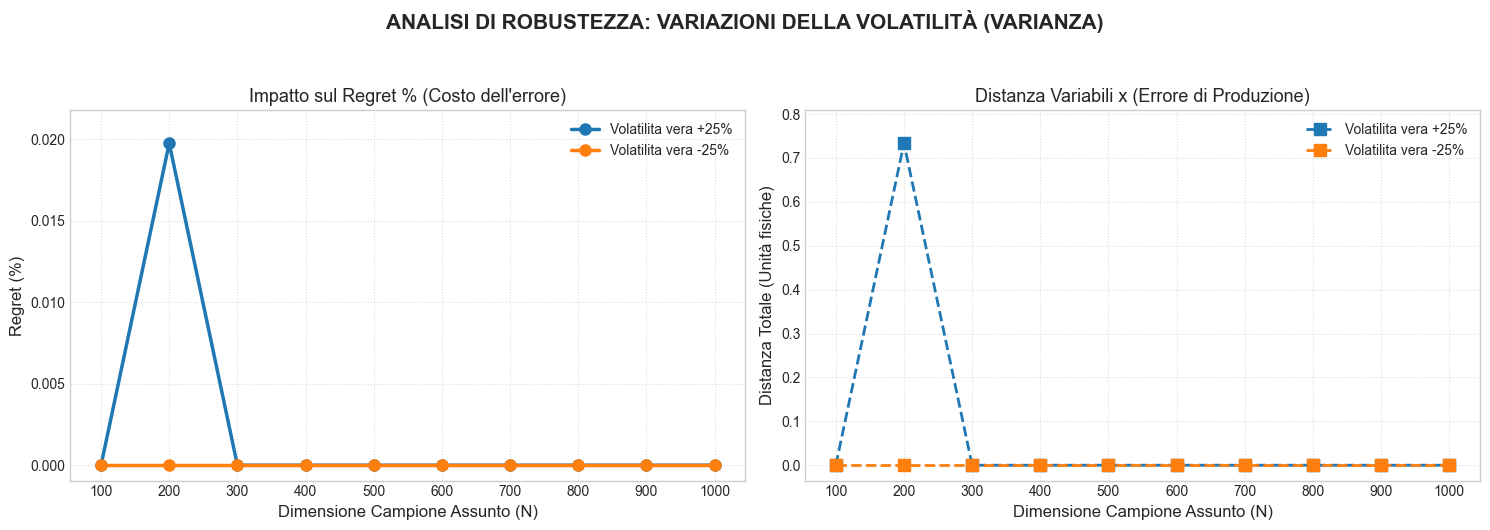

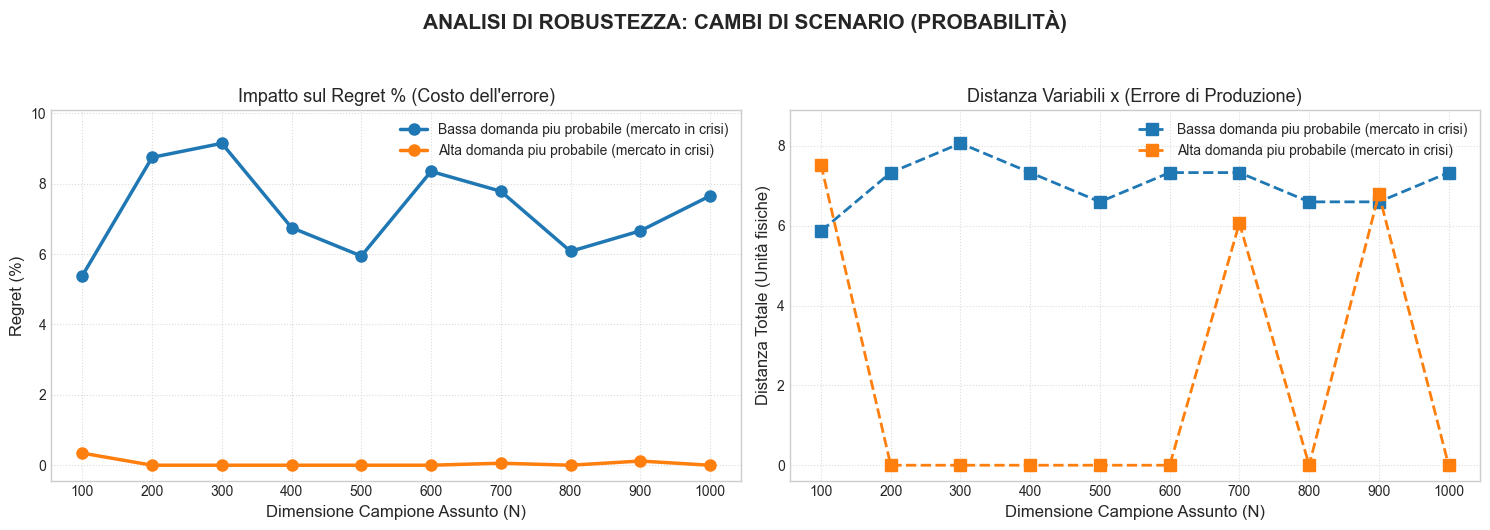

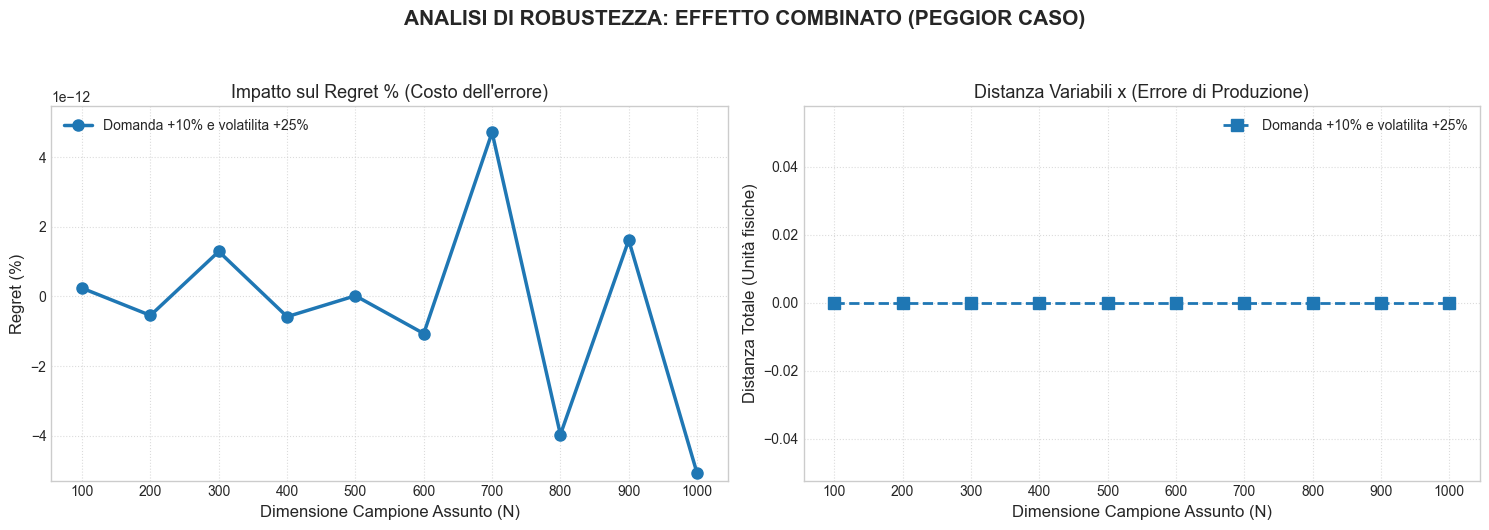

In [161]:
# GRAFICI

# Definiamo i gruppi logici
gruppi_analisi = {
    "Variazioni della Domanda Attesa": [
        "Domanda vera +10%", 
        "Domanda vera -10%"
    ],
    "Variazioni della Volatilità (Varianza)": [
        "Volatilita vera +25%", 
        "Volatilita vera -25%"
    ],
    "Cambi di Scenario (Probabilità)": [
        "Bassa domanda piu probabile (mercato in crisi)", 
        "Alta domanda piu probabile (mercato in crisi)"
    ],
    "Effetto Combinato (Peggior Caso)": [
        "Domanda +10% e volatilita +25%"
    ]
}

valori_n = sorted(df_parametri['N'].unique())

for nome_gruppo, lista_casi in gruppi_analisi.items():

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    fig.suptitle(f"ANALISI DI ROBUSTEZZA: {nome_gruppo.upper()}", fontsize=15, fontweight='bold', y=1.05)
    
    for caso in lista_casi:
        # Filtriamo il dataframe per il caso specifico
        df_caso = df_parametri[df_parametri['Caso'] == caso].sort_values(by='N')
        
        # Grafico 1: Regret Percentuale (Impatto Economico) --
        ax1.plot(df_caso['N'], df_caso['Regret_Percentuale'], marker='o', linewidth=2.5, markersize=8, label=caso)
        
        # Grafico 2: Distanza X (Impatto Operativo sui Componenti) --
        ax2.plot(df_caso['N'], df_caso['Distanza_X'], marker='s', linestyle='--', linewidth=2, markersize=8, label=caso)


    ax1.set_title("Impatto sul Regret % (Costo dell'errore)", fontsize=13)
    ax1.set_xlabel("Dimensione Campione Assunto (N)", fontsize=12)
    ax1.set_ylabel("Regret (%)", fontsize=12)
    ax1.set_xticks(valori_n)
    ax1.grid(True, linestyle=':', alpha=0.7)
    ax1.legend(loc='best')
    
    ax2.set_title("Distanza Variabili x (Errore di Produzione)", fontsize=13)
    ax2.set_xlabel("Dimensione Campione Assunto (N)", fontsize=12)
    ax2.set_ylabel("Distanza Totale (Unità fisiche)", fontsize=12)
    ax2.set_xticks(valori_n)
    ax2.grid(True, linestyle=':', alpha=0.7)
    ax2.legend(loc='best')

    y1_min, y1_max = ax1.get_ylim()
    ax1.set_ylim(y1_min * 0.95, y1_max * 1.05)
    
    y2_min, y2_max = ax2.get_ylim()
    ax2.set_ylim(y2_min * 0.95, y2_max * 1.05)
    
    plt.tight_layout()
    plt.show()

### ANALISI 2: Variazione della Distribuzione Statistica
La seconda analisi esplora la stabilità strutturale del modello al variare della natura stocastica della domanda. L'obiettivo è verificare se le decisioni di primo stadio ($x$), ottimizzate sotto assunzioni distributive standard, mantengano la loro efficacia quando la domanda reale assume altre configurazioni. 

In particola si analizza il caso con: 
1) Distyribuzione Normale
2) Poisson: Modella arrivi discreti e indipendenti. Essenziale per verificare se il modello (spesso formulato per variabili continue) soffre a causa della natura "a salti" della domanda reale.
3) Gamma: Introduce l'asimmetria (skewness). Valuta come il modello gestisce le code lunghe
4) Mistura (Bimodale): simula due stati del mercato 

In [162]:
# ROBUSTEZZA - DISTRIBUZIONI DIVERSE
casi_distribuzioni = [
    ("Vera normale", "normale"),
    ("Vera poisson", "poisson"),
    ("Vera gamma", "gamma"),
    ("Vera mistura", "mistura")
]

risultati_distribuzioni = []
data_per_grafico = []
dimensioni_campione = list(range(10, 200, 10))

for N_val in dimensioni_campione:
    print(f"\n+" + "-" * 88 + "+")
    print(f"| ESECUZIONE TEST DISTRIBUZIONI CON N = {N_val:<48} |")
    print("+" + "-" * 88 + "+")
    print(f"| {'CASO ANALIZZATO':<26} | {'REGRET %':<17} | {'DISTANZA X':<17} |")
    print("+" + "-" * 88 + "+")

    np.random.seed(set_seed)


    for nome_caso, tipo_distribuzione in casi_distribuzioni:
        
        domanda_assunta = genera_domande_per_scenario(N_val)

        domanda_vera = genera_domande_distribuzione_diversa(sample_size=N_val,tipo_distribuzione=tipo_distribuzione)

        risultato = valuta_robustezza(domanda_assunta=domanda_assunta, domanda_vera=domanda_vera, pi_assunta=pi, pi_vera=pi, sample_size=N_val)

        risultati_distribuzioni.append((f"{nome_caso}_N{N_val}", risultato))
        data_per_grafico.append({
            "Caso": nome_caso,
            "N": N_val,
            "Regret_Percentuale": risultato['regret_percentuale'],
            "Distanza_X": risultato['distanza_x']
        })

        regret_perc = f"{risultato['regret_percentuale']:.3f}%"
        dist_x = f"{risultato['distanza_x']:.2f}"
        print(f"| {nome_caso:<26} | {regret_perc:>17} | {dist_x:>17} |")
        
    # Chiusura tabella per N corrente
    print("+" + "-" * 88 + "+")

df_distribuzioni = pd.DataFrame(data_per_grafico)


+----------------------------------------------------------------------------------------+
| ESECUZIONE TEST DISTRIBUZIONI CON N = 10                                               |
+----------------------------------------------------------------------------------------+
| CASO ANALIZZATO            | REGRET %          | DISTANZA X        |
+----------------------------------------------------------------------------------------+
| Vera normale               |            0.359% |              1.47 |
| Vera poisson               |            0.436% |              6.80 |
| Vera gamma                 |            0.000% |              0.00 |
| Vera mistura               |           -0.000% |              0.00 |
+----------------------------------------------------------------------------------------+

+----------------------------------------------------------------------------------------+
| ESECUZIONE TEST DISTRIBUZIONI CON N = 20                                               |
+-----

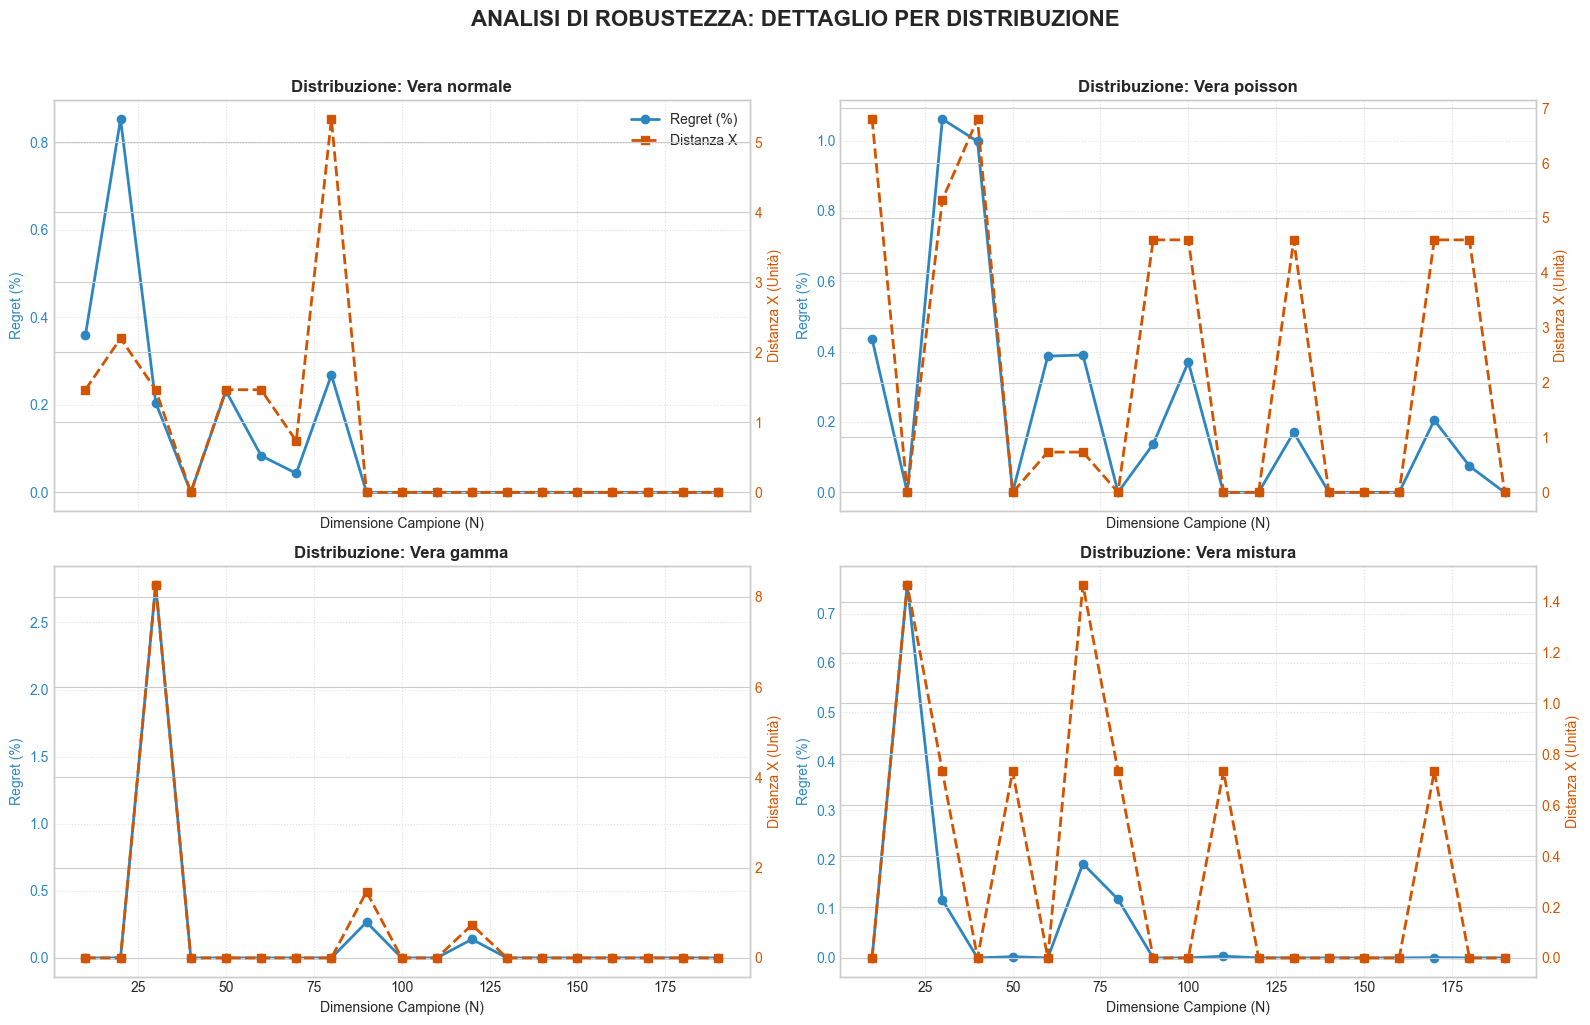

In [163]:

# Valori unici e lista dei casi
valori_n_dist = sorted(df_distribuzioni['N'].unique())
casi_dist = df_distribuzioni['Caso'].unique()

# Creiamo una figura con una griglia 2x2 (4 subplots)
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
fig.suptitle("ANALISI DI ROBUSTEZZA: DETTAGLIO PER DISTRIBUZIONE", fontsize=16, fontweight='bold', y=1.02)
axes = axes.flatten() # Rendiamo l'array di assi monodimensionale per facilitare il ciclo

for i, caso in enumerate(casi_dist):
    ax = axes[i]
    df_caso = df_distribuzioni[df_distribuzioni['Caso'] == caso].sort_values(by='N')
    
    # Doppio asse Y per Regret % e Distanza X nello stesso riquadro
    color1 = '#2E86C1' # Blu
    color2 = '#D35400' # Arancione
    
    # Asse 1: Regret %
    line1, = ax.plot(df_caso['N'], df_caso['Regret_Percentuale'], marker='o', color=color1, label='Regret (%)', linewidth=2)
    ax.set_ylabel('Regret (%)', color=color1, fontsize=10)
    ax.tick_params(axis='y', labelcolor=color1)
    
    # Asse 2: Distanza X (Gemello)
    ax2 = ax.twinx()
    line2, = ax2.plot(df_caso['N'], df_caso['Distanza_X'], marker='s', color=color2, linestyle='--', label='Distanza X', linewidth=2)
    ax2.set_ylabel('Distanza X (Unità)', color=color2, fontsize=10)
    ax2.tick_params(axis='y', labelcolor=color2)
    
    # Titolo del sottografo e griglia
    ax.set_title(f"Distribuzione: {caso}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Legenda combinata
    if i == 0:
        ax.legend([line1, line2], ['Regret (%)', 'Distanza X'], loc='upper right')

# Impostazioni finali
for ax in axes:
    ax.set_xlabel("Dimensione Campione (N)", fontsize=10)

plt.tight_layout()
plt.show()